## **Thông tin bắt buộc**

MSSV:24729251

HoTen:Lý Ngọc Anh Thư

SoMay:03



**số máy chỉ điền 2 con số, vd: 02**


## **Coding 10đ**

Dùng file `OnlineRetail.csv` (cùng thư mục với notebook, bộ dữ liệu *Online Retail* trên Kaggle). Mỗi dòng là một mặt hàng trong một hóa đơn bán lẻ trực tuyến của một cửa hàng ở Anh (2010-2011).

| Cột | Mô tả |
|---|---|
| InvoiceNo | Mã hóa đơn. Mã bắt đầu bằng chữ `C` là hóa đơn bị hủy. Một hóa đơn có thể có nhiều dòng. |
| StockCode | Mã sản phẩm. |
| Description | Tên sản phẩm. |
| Quantity | Số lượng mua. Âm nghĩa là hàng bị trả lại / hủy. |
| InvoiceDate | Thời điểm lập hóa đơn (chuỗi, định dạng tháng/ngày/năm giờ:phút). Đổi tên thành invoice_time. |
| UnitPrice | Đơn giá một sản phẩm (GBP). Đổi tên thành unit_price. |
| CustomerID | Mã khách hàng. Đổi tên thành cust_id. |
| Country | Quốc gia của khách hàng. Đổi tên thành country. |

**Lưu ý:** file csv này không đọc được bằng encoding mặc định, hãy dùng `encoding='latin1'`.


* import thư viện

In [1]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

### **Discovery & Structuring (1.9đ)**

* đọc file csv vào biến df, in 5 dòng cuối cùng (0.2đ)

In [2]:
df = pd.read_csv("OnlineRetail.csv", encoding="ISO-8859-1")
df.tail()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,12/9/2011 12:50,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,12/9/2011 12:50,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,12/9/2011 12:50,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,12/9/2011 12:50,4.15,12680.0,France
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,12/9/2011 12:50,4.95,12680.0,France


* đọc thông tin data (0.15đ)

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


* in thông tin số dòng và số cột (0.15đ)

In [4]:
print("Số dòng:", df.shape[0])
print("Số cột:", df.shape[1])

Số dòng: 541909
Số cột: 8


* in ra số quốc gia (Country) trong bộ data và 4 quốc gia có nhiều dòng nhất (0.15đ)

In [5]:
print("Số quốc gia:", df["Country"].nunique())

Số quốc gia: 38


In [6]:
df["Country"].value_counts().head(4)

Country
United Kingdom    495478
Germany             9495
France              8557
EIRE                8196
Name: count, dtype: int64

* đổi tên 4 cột: InvoiceDate --> invoice_time, UnitPrice --> unit_price, CustomerID --> cust_id, Country --> country (0.2đ)

In [7]:
df = df.rename(columns={"InvoiceDate": "invoice_time", "UnitPrice": "unit_price", "CustomerID": "cust_id", "Country": "country"})

* in lại danh sách các cột sau khi rename (0.15đ)

In [8]:
df.columns.tolist()

['InvoiceNo',
 'StockCode',
 'Description',
 'Quantity',
 'invoice_time',
 'unit_price',
 'cust_id',
 'country']

* Tạo dataframe profile_df bao gồm dtype, nunique, missing_count, missing_percentage. Sắp xếp giảm dần theo missing_count. (0.5đ)

In [9]:
profile_df = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "nunique": df.nunique(dropna=True),
    "missing_count": df.isna().sum(),
    "missing_percentage": (df.isna().mean() * 100)
}).sort_values("missing_count", ascending=False)
profile_df

,dtype,nunique,missing_count,missing_percentage
cust_id,float64,4372,135080,24.926694
Description,object,4223,1454,0.268311
StockCode,object,4070,0,0.000000
InvoiceNo,object,25900,0,0.000000
Quantity,int64,722,0,0.000000
invoice_time,object,23260,0,0.000000
unit_price,float64,1630,0,0.000000
country,object,38,0,0.000000


* tìm số dòng thỏa điều kiện country là France và Quantity từ 10 trở lên (0.2đ)

In [10]:
((df["country"] == "France") & (df["Quantity"] >= 10)).sum()

np.int64(4664)

* cho biết số dòng có InvoiceNo bắt đầu bằng chữ C (hóa đơn hủy) và country khác United Kingdom (0.2đ). Gợi ý: .str.startswith()

In [11]:
(df["invoice_time"].astype(str).str.startswith("C") & (df["country"] != "United Kingdom")).sum()

np.int64(0)

### **Cleaning**

#### **Duplicated & missing data (3.05đ)**

Duplicate count (0.4đ)
* In số dòng trùng cả bản ghi.
* In thêm số dòng trùng theo cặp cột InvoiceNo và Description (một sản phẩm xuất hiện nhiều lần trong cùng hóa đơn). Gợi ý: subset=[...]

In [12]:
print("Số dòng trùng toàn bộ bản ghi:", df.duplicated().sum())
print("Số dòng trùng theo InvoiceNo và Description:", df.duplicated(subset=["InvoiceNo", "Description"]).sum())

Số dòng trùng toàn bộ bản ghi: 5268
Số dòng trùng theo InvoiceNo và Description: 10869


* xoá số dòng duplicated cả bản ghi (0.25đ)

In [13]:
df = df.drop_duplicates()

* in lại số dòng trùng và shape sau khi xoá (0.25đ)

In [14]:
print("Số dòng trùng còn lại:", df.duplicated().sum())
print("Shape sau khi xóa:", df.shape)

Số dòng trùng còn lại: 0
Shape sau khi xóa: (536641, 8)


missing_report (0.4đ)
* Kiểm tra dữ liệu có missing không?
* Nếu có, tạo missing_report gồm 3 cột: column_name, missing_count, missing_percentage
* missing_percentage làm tròn 2 chữ số thập phân
* Sắp xếp missing_report tăng dần theo missing_percentage
* Chỉ giữ các dòng có missing_count khác 0

In [15]:
missing_count = df.isna().sum()
missing_report = pd.DataFrame({
    "column_name": missing_count.index,
    "missing_count": missing_count.values,
    "missing_percentage": (missing_count.values / len(df) * 100).round(2)
})
missing_report = missing_report[missing_report["missing_count"] != 0].sort_values("missing_percentage", ascending=True)
missing_report

,column_name,missing_count,missing_percentage
2,Description,1454,0.27
6,cust_id,135037,25.16


Missing-value bar chart (0.4đ)
* Vẽ bar chart cho missing_report với x là column_name, y là missing_percentage
* xlabel là tên cột, ylabel là tỷ lệ thiếu (%)

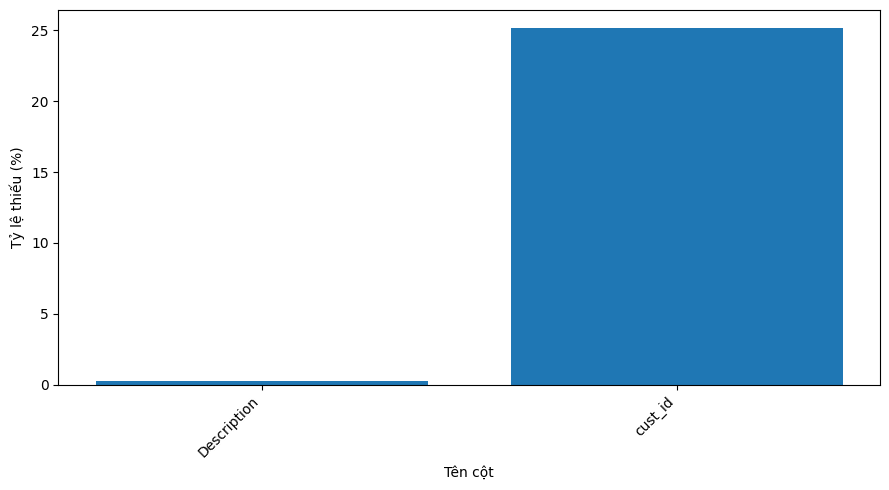

In [16]:
plt.figure(figsize=(9, 5))
plt.bar(missing_report["column_name"], missing_report["missing_percentage"])
plt.xlabel("Tên cột")
plt.ylabel("Tỷ lệ thiếu (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

* tạo cột cust_missing cho biết cust_id có bị thiếu hay không (True/False hoặc 1/0) (0.25đ)

In [17]:
df["cust_missing"] = df["cust_id"].isna()

* cust_missing_rate = Chỉ xét 4 quốc gia có nhiều dòng nhất. Nhóm theo country, tính mean của cột cust_missing rồi nhân 100 để ra tỷ lệ thiếu (%). Sắp xếp giảm dần và đổi tên thành cust_missing_pct. (0.25đ)

In [18]:
top4_countries = df["country"].value_counts().head(4).index
cust_missing_rate = (df[df["country"].isin(top4_countries)].groupby("country")["cust_missing"].mean() * 100).sort_values(ascending=False).rename("cust_missing_pct")
cust_missing_rate

country
United Kingdom    27.242913
EIRE               8.663245
France             0.772743
Germany            0.000000
Name: cust_missing_pct, dtype: float64

* Vẽ bar chart ngang tỷ lệ thiếu cust_id theo country. xlabel là tỷ lệ thiếu (%), ylabel là quốc gia. (0.25đ)

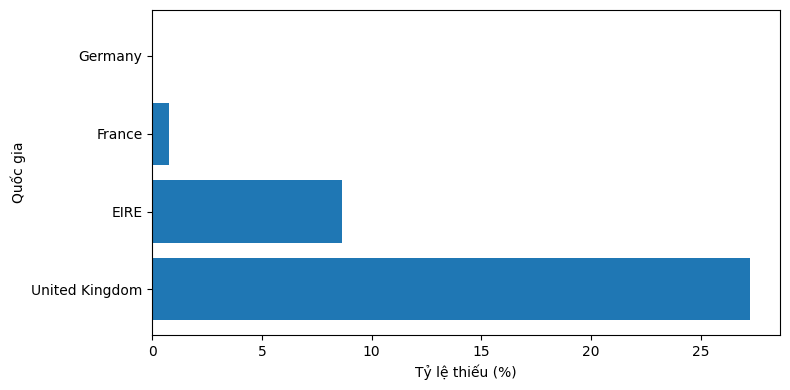

In [19]:
plt.figure(figsize=(8, 4))
plt.barh(cust_missing_rate.index, cust_missing_rate.values)
plt.xlabel("Tỷ lệ thiếu (%)")
plt.ylabel("Quốc gia")
plt.tight_layout()
plt.show()

Fill missing (0.4đ)
* Description: điền 'NO_NAME'.
* Kiểm tra lại

In [20]:
df["Description"] = df["Description"].fillna("NO_NAME")

In [21]:
print("Số giá trị thiếu trong Description:", df["Description"].isna().sum())

Số giá trị thiếu trong Description: 0


Invalid values (0.2đ)
* Quantity <= 0 (hàng trả lại / hóa đơn hủy) và unit_price <= 0 (hàng tặng / điều chỉnh sổ sách) không phải giao dịch bán hàng thật sự.
* Tạo cột is_return: bằng 1 nếu InvoiceNo bắt đầu bằng chữ C, ngược lại bằng 0. (gợi ý startswith)
* Sau đó giữ lại trong df các dòng có Quantity > 0 và unit_price > 0. In shape trước và sau khi lọc.

In [22]:
df["is_return"] = df["InvoiceNo"].astype(str).str.startswith("C").astype(int)
print("Shape trước khi lọc:", df.shape)
df = df[(df["Quantity"] > 0) & (df["unit_price"] > 0)].copy()
print("Shape sau khi lọc:", df.shape)

Shape trước khi lọc: (536641, 10)


Shape sau khi lọc: (524878, 10)


#### **Outlier (2.5đ)**

* num_df chỉ chứa Quantity và unit_price (0.2đ)

In [23]:
num_df = df[["Quantity", "unit_price"]].copy()

bound_table with concat (0.5đ)
* Tạo dataframe bound_table bằng CONCAT
* bound_table gồm các cột Q1, Q3, IQR, lower_bound, upper_bound, outlier_count
* Q1 là phân vị 15%, Q3 là phân vị 85%

In [24]:
q1 = num_df.quantile(0.15)
q3 = num_df.quantile(0.85)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr
outlier_count = ((num_df < lower_bound) | (num_df > upper_bound)).sum()
bound_table = pd.concat([q1.rename("Q1"), q3.rename("Q3"), iqr.rename("IQR"), lower_bound.rename("lower_bound"), upper_bound.rename("upper_bound"), outlier_count.rename("outlier_count")], axis=1)
bound_table

,Q1,Q3,IQR,lower_bound,upper_bound,outlier_count
Quantity,1.00,12.00,11.00,-15.50,28.50,26837
unit_price,0.83,5.79,4.96,-6.61,13.23,12155


df_filtered outlier filter (0.4đ)
* df_filtered lọc lại dữ liệu từ df, loại các dòng có ít nhất một cột số trong num_df nằm ngoài [lower_bound, upper_bound]

In [25]:
mask = pd.Series(True, index=df.index)
for col in num_df.columns:
    mask &= df[col].between(lower_bound[col], upper_bound[col])
df_filtered = df.loc[mask].copy()
print("Shape trước lọc outlier:", df.shape)
print("Shape sau lọc outlier:", df_filtered.shape)

Shape trước lọc outlier: (524878, 10)
Shape sau lọc outlier: (485906, 10)


df_clipped (0.3đ)
* Tạo df_clipped từ df bằng clip kéo ngưỡng về chặn trên chặn dưới (chỉ áp dụng cho các cột trong num_df)

In [26]:
df_clipped = df.copy()
for col in num_df.columns:
    df_clipped[col] = df_clipped[col].clip(lower=lower_bound[col], upper=upper_bound[col])
df_clipped.head()

,InvoiceNo,StockCode,Description,Quantity,invoice_time,unit_price,cust_id,country,cust_missing,is_return
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6.0,12/1/2010 8:26,2.55,17850.0,United Kingdom,False,0
1,536365,71053,WHITE METAL LANTERN,6.0,12/1/2010 8:26,3.39,17850.0,United Kingdom,False,0
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8.0,12/1/2010 8:26,2.75,17850.0,United Kingdom,False,0
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6.0,12/1/2010 8:26,3.39,17850.0,United Kingdom,False,0
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6.0,12/1/2010 8:26,3.39,17850.0,United Kingdom,False,0


Histogram of unit_price (0.25đ)
* vẽ histogram cho cột unit_price trong df_filtered
* title là "phân phối unit_price"
* xlabel là "Đơn giá (GBP)"

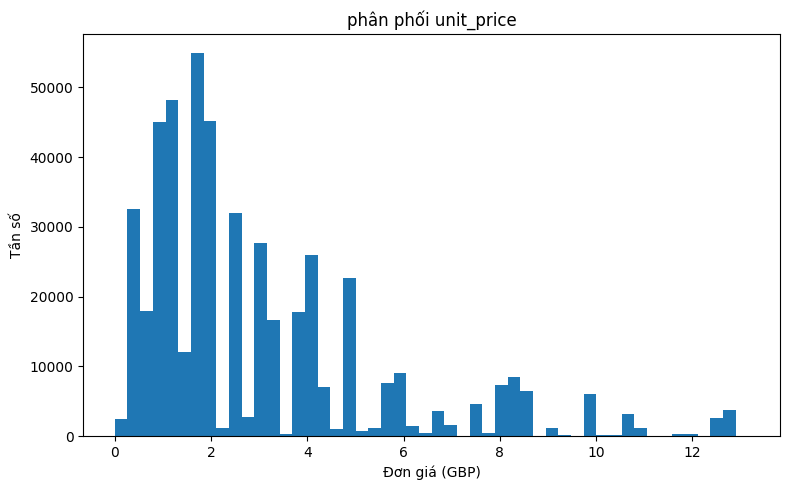

In [27]:
plt.figure(figsize=(8, 5))
plt.hist(df_filtered["unit_price"].dropna(), bins=50)
plt.title("phân phối unit_price")
plt.xlabel("Đơn giá (GBP)")
plt.ylabel("Tần số")
plt.tight_layout()
plt.show()

Is unit_price skewed? Print skew, kurtosis, mean, median (0.6đ)
* Dùng cột unit_price của df_filtered (bỏ giá trị thiếu). Dữ liệu có lệch không? In ra skew, kurtosis, mean, median.
* Từ kurtosis, so với phân phối chuẩn thì đỉnh nhọn hơn hay hai đuôi dày hơn?

In [28]:
price = df_filtered["unit_price"].dropna()
price_skew = price.skew()
price_kurtosis = price.kurt()
print("skew:", price_skew)
print("kurtosis:", price_kurtosis)
print("mean:", price.mean())
print("median:", price.median())
if price_skew > 0:
    print("Phân phối lệch phải.")
elif price_skew < 0:
    print("Phân phối lệch trái.")
else:
    print("Phân phối đối xứng theo skew.")
if price_kurtosis > 0:
    print("So với phân phối chuẩn, phân phối có đuôi dày hơn (excess kurtosis > 0).")
elif price_kurtosis < 0:
    print("So với phân phối chuẩn, phân phối có đuôi mỏng hơn (excess kurtosis < 0).")
else:
    print("Kurtosis gần mức của phân phối chuẩn.")

skew: 1.6061717417125139
kurtosis: 2.4130393153096907
mean: 3.006674303260302
median: 2.1
Phân phối lệch phải.
So với phân phối chuẩn, phân phối có đuôi dày hơn (excess kurtosis > 0).


Create price_log (0.25đ)

* Tạo cột price_log trong df_filtered bằng log1p.

In [29]:
df_filtered["price_log"] = np.log1p(df_filtered["unit_price"])

### **Univariate Analysis (0.55đ)**

* thống kê mô tả cho 3 cột Quantity, unit_price và price_log trong df_filtered (0.3đ)

In [30]:
df_filtered[["Quantity", "unit_price", "price_log"]].describe()

,Quantity,unit_price,price_log
count,485906.000000,485906.000000,485906.000000
mean,6.000566,3.006674,1.217747
std,6.336520,2.582798,0.566415
min,1.000000,0.001000,0.001000
25%,1.000000,1.250000,0.810930
50%,3.000000,2.100000,1.131402
75%,10.000000,4.130000,1.635106
max,28.000000,13.160000,2.650421


* In skew, kurtosis, mean, median của price_log. Vẽ hai histogram cạnh nhau: unit_price và price_log. (0.25đ)

price_log skew: 0.42183076183182905
price_log kurtosis: -0.5087971484235072
price_log mean: 1.2177474487755158
price_log median: 1.1314021114911006


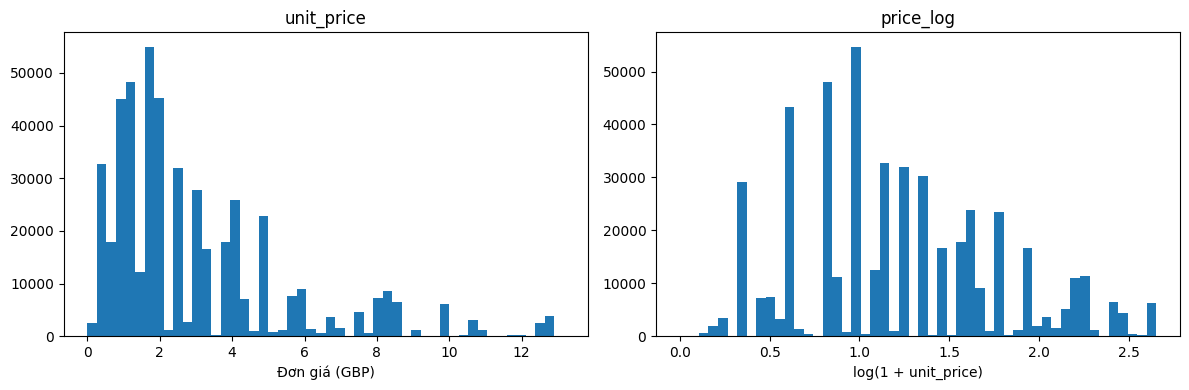

In [31]:
log_price = df_filtered["price_log"].dropna()
print("price_log skew:", log_price.skew())
print("price_log kurtosis:", log_price.kurt())
print("price_log mean:", log_price.mean())
print("price_log median:", log_price.median())
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df_filtered["unit_price"].dropna(), bins=50)
axes[0].set_title("unit_price")
axes[0].set_xlabel("Đơn giá (GBP)")
axes[1].hist(log_price, bins=50)
axes[1].set_title("price_log")
axes[1].set_xlabel("log(1 + unit_price)")
plt.tight_layout()
plt.show()

### **Bivariate & Multivariate Analysis (1.65đ)**

Xem mối quan hệ giữa các biến.

Feature engineering (0.2đ)
* Đổi invoice_time của df_filtered sang kiểu datetime. Gợi ý: to_datetime
* Tạo các cột trong df_filtered: sales_value = Quantity * unit_price, month_no (tháng), hour_of_day (giờ). Gợi ý: .dt.month...

In [32]:
df_filtered["invoice_time"] = pd.to_datetime(df_filtered["invoice_time"], errors="coerce")
df_filtered["sales_value"] = df_filtered["Quantity"] * df_filtered["unit_price"]
df_filtered["month_no"] = df_filtered["invoice_time"].dt.month
df_filtered["hour_of_day"] = df_filtered["invoice_time"].dt.hour
df_filtered["day_name"] = df_filtered["invoice_time"].dt.day_name()
df_filtered[["invoice_time", "sales_value", "month_no", "hour_of_day", "day_name"]].head()

,invoice_time,sales_value,month_no,hour_of_day,day_name
0,2010-12-01 08:26:00,15.30,12,8,Wednesday
1,2010-12-01 08:26:00,20.34,12,8,Wednesday
2,2010-12-01 08:26:00,22.00,12,8,Wednesday
3,2010-12-01 08:26:00,20.34,12,8,Wednesday
4,2010-12-01 08:26:00,20.34,12,8,Wednesday


* Heatmap (0.25đ): Correlation heatmap giữa các cột số, bao gồm Quantity, unit_price, sales_value, month_no, hour_of_day.

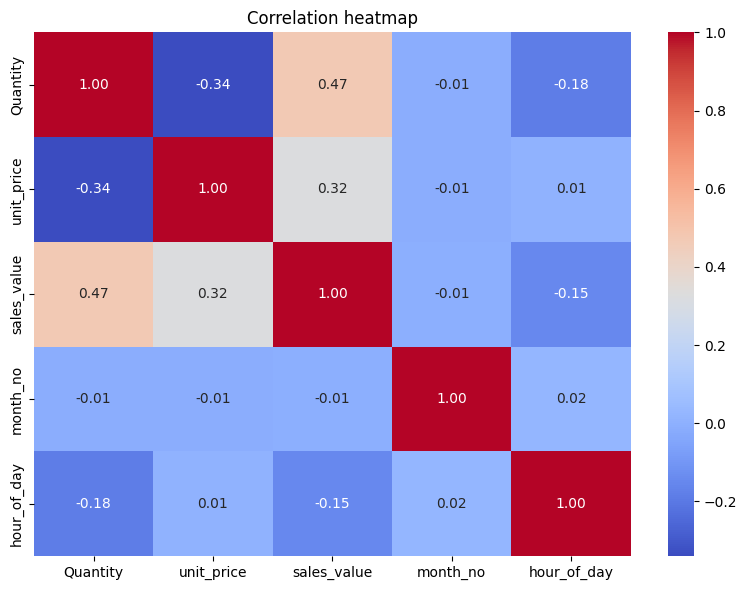

In [33]:
corr_cols = ["Quantity", "unit_price", "sales_value", "month_no", "hour_of_day"]
plt.figure(figsize=(8, 6))
sns.heatmap(df_filtered[corr_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation heatmap")
plt.tight_layout()
plt.show()

* df_filtered group by theo day_name, tính count, mean, max của sales_value (0.25đ), gợi ý: .agg

In [34]:
day_sales = df_filtered.groupby("day_name")["sales_value"].agg(["count", "mean", "max"])
day_sales

,count,mean,max
day_name,,,
Friday,73657,13.276693,306.00
Monday,85864,11.886561,362.60
Sunday,59704,10.131977,357.00
Thursday,91913,13.506837,306.00
Tuesday,90785,12.583293,330.72
Wednesday,83983,12.825522,306.00


* df_filtered group by theo country (4 quốc gia nhiều dòng nhất), tính count và mean của sales_value. Sắp xếp giảm dần theo mean. (0.35đ)

In [35]:
country_sales = df_filtered[df_filtered["country"].isin(top4_countries)].groupby("country")["sales_value"].agg(["count", "mean"]).sort_values("mean", ascending=False)
country_sales

,count,mean
country,,
EIRE,6779,21.047942
Germany,8056,19.715005
France,7520,18.499205
United Kingdom,448263,11.838349


* Tạo pivot median sales_value theo month_no (hàng) và country (cột), chỉ xét 3 quốc gia Germany, France, Spain. Vẽ heatmap. (0.6đ). Gợi ý: dùng isin để lọc, pivot_table, index là hàng, columns là cột, values, aggfunc gọi hàm. Sau đó vẽ heatmap

In [36]:
pivot_sales = df_filtered[df_filtered["country"].isin(["Germany", "France", "Spain"])].pivot_table(index="month_no", columns="country", values="sales_value", aggfunc="median")
pivot_sales

country,France,Germany,Spain
month_no,,,
1,17.4,15.00,15.000
2,15.6,17.00,15.300
3,15.6,15.85,15.900
4,15.3,17.70,16.200
5,16.5,16.60,17.400
6,17.4,15.00,15.000
7,15.3,15.30,10.080
8,16.5,16.50,8.450
9,16.6,16.50,16.500


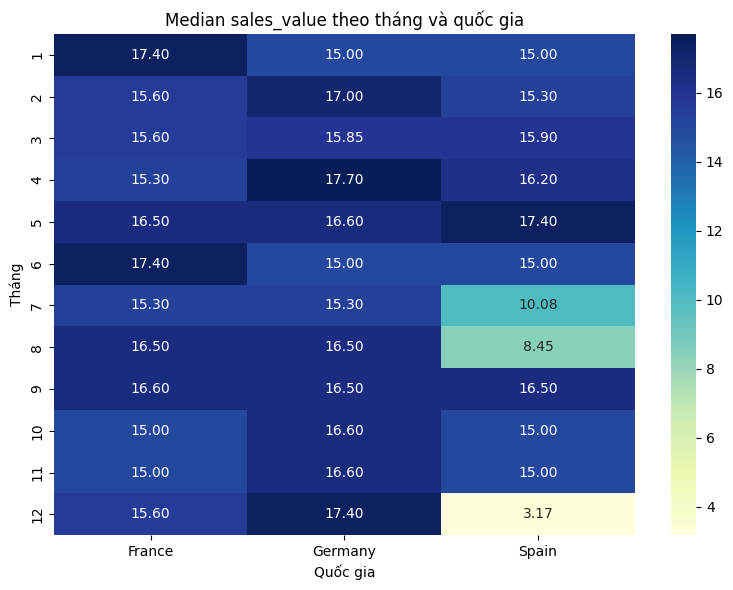

In [37]:
plt.figure(figsize=(8, 6))
sns.heatmap(pivot_sales, annot=True, fmt=".2f", cmap="YlGnBu")
plt.title("Median sales_value theo tháng và quốc gia")
plt.xlabel("Quốc gia")
plt.ylabel("Tháng")
plt.tight_layout()
plt.show()

### **Publishing (0.35đ)**

* Lưu 500 dòng đầu của df_filtered ra file Excel, đặt tên shop_final.xlsx, không lưu cột index (0.2đ)

In [38]:
df_filtered.head(500).to_excel("shop_final.xlsx", index=False)
print("Đã lưu shop_final.xlsx")

Đã lưu shop_final.xlsx


* Sau đó lưu 500 dòng cuối của df_filtered ra file HTML, đặt tên shop_final.html, không lưu cột index (0.15đ)

In [39]:
df_filtered.tail(500).to_html("shop_final.html", index=False)
print("Đã lưu shop_final.html")

Đã lưu shop_final.html
